1- discover data and unzip it

In [538]:

from pathlib import Path 
import zipfile 
import os 
import numpy as np 
from PIL import Image 

In [539]:
zip_path=r"C:\Users\marim\Downloads\flowers_dataset.zip"

In [540]:
extract_dir = Path("flowers_data")


In [541]:
if not extract_dir.exists():
    with zipfile.ZipFile(zip_path,'r') as z :
        z.extractall(extract_dir)

In [542]:
os.listdir(extract_dir)

['data set flowers']

In [543]:
data_dir= extract_dir /"data set flowers" /"flowers"

In [544]:
classes= sorted(os.listdir(data_dir))

In [545]:
print(classes)

['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


In [546]:
for cls in classes :
    print(len(os.listdir(data_dir/cls)))

764
1052
784
733
984


In [547]:
first_class = classes[0]
first_image_path= data_dir / first_class / os.listdir(data_dir /first_class)[0]
img = Image.open(first_image_path)
print("Image size:" , img.size)
print("Image mode:", img.mode)
      

Image size: (320, 263)
Image mode: RGB


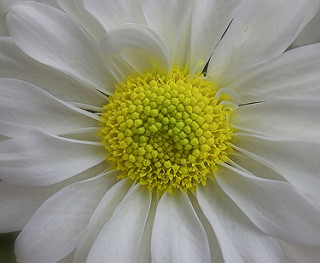

In [548]:
display(img)

In [549]:

images = []
labels = []
img_size=(64,64)
for idx, cls in enumerate(classes):
    class_dir = data_dir / cls

    for img_name in os.listdir(class_dir):
        img_path = class_dir / img_name

        try:
            img = Image.open(img_path)

            img = img.convert("RGB")

            img = img.resize(img_size)

            img_array = np.array(img) / 255.0

            images.append(img_array)
            labels.append(idx)

        except Exception as e:
            print(f"Error loading {img_path}: {e}")


X = np.array(images)
y = np.array(labels)



In [550]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Total images:", len(X))
print("Total labels:", len(y))

X shape: (4317, 64, 64, 3)
y shape: (4317,)
Total images: 4317
Total labels: 4317


In [551]:
from sklearn.model_selection import train_test_split
x_train , x_temp , y_train , y_temp = train_test_split(
    X,
    y,
    test_size=0.3 ,
    stratify= y ,
    random_state=42

)
X_val, X_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.50, # 15% for test and 15% for validation 
    stratify=y_temp,
    random_state=42
)


In [552]:
print("Training shape:", x_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

print("\nNumber of images in every class (train):", np.bincount(y_train))
print("Number of images in every class (validation):", np.bincount(y_val))
print("Number of images in every class (testing):", np.bincount(y_test))

Training shape: (3021, 64, 64, 3)
Validation shape: (648, 64, 64, 3)
Testing shape: (648, 64, 64, 3)

Number of images in every class (train): [535 736 549 513 688]
Number of images in every class (validation): [114 158 118 110 148]
Number of images in every class (testing): [115 158 117 110 148]


feature Extraction 

In [553]:
from skimage.feature import hog 
from sklearn.preprocessing import StandardScaler


In [554]:
def extract_features(img, show_steps=False):

    # A) HOG Feature Extraction
    hog_features, hog_image = hog(
        img,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        channel_axis=-1,
        visualize=True
    )

    if show_steps:
        plt.figure(figsize=(10, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(img)
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(hog_image, cmap="gray")
        plt.title("HOG Image")
        plt.axis("off")

        plt.show()

        print("HOG vector shape:", hog_features.shape)
        print("First 20 HOG values:")
        print(hog_features[:20])

    # B) Color Histogram
    color_hist = []

    for channel in range(3):

        hist, bin_edges = np.histogram(
            img[:, :, channel],
            bins=32,
            range=(0, 1)
        )

        color_hist.extend(hist)

        if show_steps:
            channel_names = ["Red", "Green", "Blue"]
            channel_colors = ["red", "green", "blue"]

            plt.figure(figsize=(6, 3))

            plt.bar(
                bin_edges[:-1],
                hist,
                width=1/32,
                color=channel_colors[channel]
            )

            plt.title(channel_names[channel] + " Histogram")
            plt.xlabel("Pixel Intensity")
            plt.ylabel("Pixel Count")
            plt.show()

            print(channel_names[channel], "histogram:")
            print(hist)

    color_hist = np.array(color_hist)

    # C) Combine Features
    combined_features = np.concatenate([
        hog_features,
        color_hist
    ])

    if show_steps:
        print("\nHOG dimensions:", len(hog_features))
        print("Color dimensions:", len(color_hist))
        print("Final dimensions:", len(combined_features))

        print("\nFirst 20 combined values:")
        print(combined_features[:20])

    return combined_features

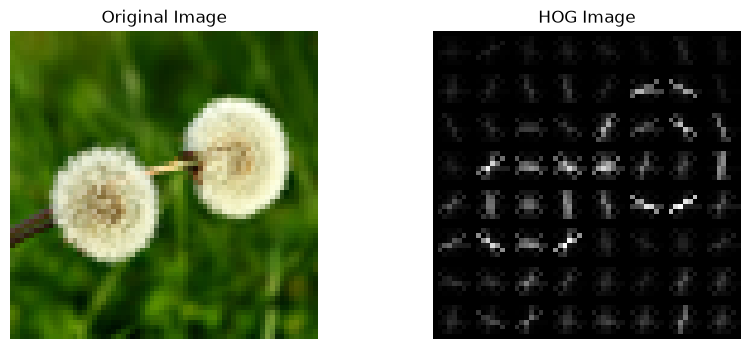

HOG vector shape: (1764,)
First 20 HOG values:
[0.15503708 0.07845764 0.15213599 0.05906542 0.26109709 0.05300066
 0.01949125 0.1311202  0.15638868 0.25257437 0.06252683 0.26109709
 0.26109709 0.07113779 0.05430958 0.01964293 0.         0.10485484
 0.26109709 0.19445855]


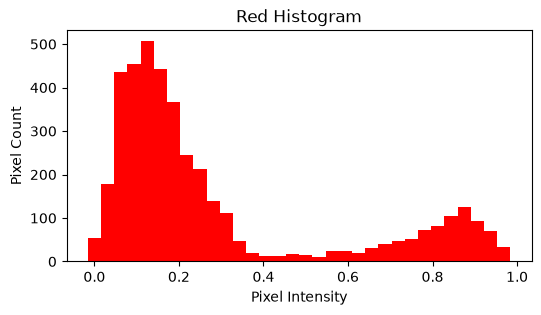

Red histogram:
[ 55 179 435 454 506 443 367 244 212 138 111  48  20  12  13  18  15  10
  25  24  19  31  40  46  51  72  81 105 126  92  71  33]


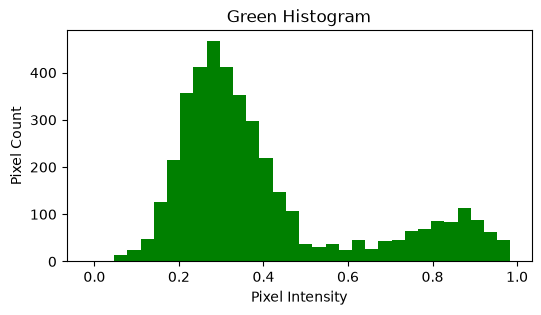

Green histogram:
[  0   2  14  24  48 126 214 356 413 466 411 352 298 219 147 106  38  31
  37  24  46  26  43  45  64  69  85  83 113  88  63  45]


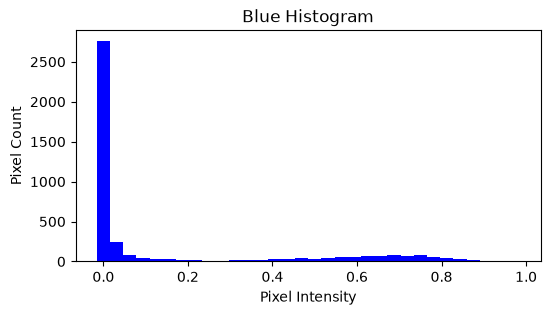

Blue histogram:
[2754  248   84   44   35   32   20   18   12    8   19   22   21   27
   32   41   29   42   54   56   63   64   76   67   77   60   44   27
   13    5    2    0]

HOG dimensions: 1764
Color dimensions: 96
Final dimensions: 1860

First 20 combined values:
[0.15503708 0.07845764 0.15213599 0.05906542 0.26109709 0.05300066
 0.01949125 0.1311202  0.15638868 0.25257437 0.06252683 0.26109709
 0.26109709 0.07113779 0.05430958 0.01964293 0.         0.10485484
 0.26109709 0.19445855]


In [555]:
sample_features = extract_features(sample_img, show_steps=True)

In [556]:
X_train_feat = np.array([
    extract_features(img) for img in x_train
])

X_val_feat = np.array([
    extract_features(img) for img in X_val
])

X_test_feat = np.array([
    extract_features(img) for img in X_test
])

print("Train:", X_train_feat.shape)
print("Validation:", X_val_feat.shape)
print("Test:", X_test_feat.shape)

Train: (3021, 1860)
Validation: (648, 1860)
Test: (648, 1860)


In [557]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_feat)

X_val_scaled = scaler.transform(X_val_feat)

X_test_scaled = scaler.transform(X_test_feat)

print("Scaled Train:", X_train_scaled.shape)
print("Scaled Validation:", X_val_scaled.shape)
print("Scaled Test:", X_test_scaled.shape)

print("Final feature dimension:", X_train_scaled.shape[1])

Scaled Train: (3021, 1860)
Scaled Validation: (648, 1860)
Scaled Test: (648, 1860)
Final feature dimension: 1860


In [558]:
import numpy as np
from pathlib import Path


output_dir = Path("processed_data")
output_dir.mkdir(exist_ok=True)


np.savez_compressed(
    output_dir / "flower_data.npz",
    X_train=X_train_scaled,
    X_val=X_val_scaled,
    X_test=X_test_scaled,
    y_train=y_train,
    y_val=y_val,
    y_test=y_test
)

print("Data saved successfully!")

Data saved successfully!


In [559]:
data = np.load("processed_data/flower_data.npz")

for name in data.files:
    print(name, data[name].shape)
    

X_train (3021, 1860)
X_val (648, 1860)
X_test (648, 1860)
y_train (3021,)
y_val (648,)
y_test (648,)
